# 05 — Selección y evaluación de modelos de texto (multiclase)

**Tu parte del TP:** comparar clasificadores, ajustar hiperparámetros, seleccionar según una métrica adecuada y evaluar el modelo final.

**Dataset real de la cátedra:** `balanced_mental_health_dataset_sampled.csv`, utilizado en **Clase 6 - NLP.ipynb**, sección de clasificación de textos (en ese ejemplo se comparan etiquetas con una API). Este notebook **adapta** ese dataset para entrenar modelos de Scikit-Learn: el entrenamiento con este archivo no es un ejercicio copiado literalmente de la cátedra. Los métodos sí vienen de las clases.

**Importante:** sus cuatro clases (`Normal`, `Anxiety`, `Depression`, `Personality disorder`) **no son sentimientos**. Es una práctica técnica de clasificación multiclase, no un modelo clínico, ni un sustituto de los tweets del TP. Los textos están en inglés.

**Plan:** carga/preparación ya resueltas → baseline con Logistic Regression → comparar Naive Bayes → optimización con GridSearchCV → evaluación **final** solo cuando se haya decidido el modelo. Más adelante, SVM y Random Forest en otro notebook o sección.


## 1. Carga y preparación del dataset (resuelto)

Se eliminan únicamente textos faltantes o vacíos. No hacemos stemming, lematización ni stopwords, porque este notebook trata de **selección de modelos**. El procesamiento textual que aprende estadísticas se deja dentro del Pipeline.

In [21]:
from pathlib import Path
import pandas as pd

ruta = Path('datasets/balanced_mental_health_dataset_sampled.csv')
if not ruta.exists():
    ruta = Path('../datasets/balanced_mental_health_dataset_sampled.csv')

if not ruta.exists():
    raise FileNotFoundError(f'No se encontró el dataset en: {ruta.resolve()}')

df = pd.read_csv(ruta)
print('Dimensiones originales:', df.shape)
print('Valores faltantes por columna:')
print(df[['statement', 'status']].isna().sum())

df = df.dropna(subset=['statement', 'status']).copy()
df['statement'] = df['statement'].astype(str).str.strip()
df = df[df['statement'] != ''].copy()

print('Dimensiones luego de quitar textos faltantes o vacíos:', df.shape)
print('Cantidad de observaciones por clase:')
print(df['status'].value_counts())
df[['statement','status']].head()


Dimensiones originales: (400, 2)
Valores faltantes por columna:
statement    12
status        0
dtype: int64
Dimensiones luego de quitar textos faltantes o vacíos: (388, 2)
Cantidad de observaciones por clase:
status
Normal                  104
Depression              101
Anxiety                 100
Personality disorder     83
Name: count, dtype: int64


,statement,status
0,How can I function with unwanted thoughts that...,Personality disorder
1,feeling lost naked and confused jk sort of no ...,Normal
2,Know I'm going to get dementia I'm 24 and rece...,Anxiety
3,Waking and feeling anxious because you think y...,Anxiety
4,I figured I would rant in a depression sub mor...,Depression


**Interpretación:** mirá si las clases están equilibradas. En el TP esto influirá sobre la elección de `scoring`. Como los textos pueden ser sensibles, no hace falta copiarlos en tus conclusiones; trabajaremos con cantidades y métricas agregadas.

## 2. Definir X, y y reservar test (resuelto)

Separamos **texto sin vectorizar**, tal como hicimos en el notebook 4. Conservar `X_test` intacto es clave: no se usa para elegir hiperparámetros.

In [22]:
from sklearn.model_selection import train_test_split

X = df['statement']
y = df['status']

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('Entrenamiento:', X_train.shape, 'Prueba:', X_test.shape)
print('Etiquetas en entrenamiento:')
print(y_train.value_counts())


Entrenamiento: (310,) Prueba: (78,)
Etiquetas en entrenamiento:
status
Normal                  83
Depression              81
Anxiety                 80
Personality disorder    66
Name: count, dtype: int64


## 3. Primer clasificador: Logistic Regression (resuelto como modelo base)

**Fuente del método:** resolución de los ejercicios de NLP de la Clase 6. El Pipeline entrena TF-IDF y Logistic Regression juntos. Por ahora entrenamos y observamos cómo se usa, sin consultar el conjunto de prueba.

In [23]:
from sklearn.pipeline import Pipeline
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

pipeline_lr = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

pipeline_lr.fit(X_train, y_train)
print('Pipeline entrenado:', pipeline_lr)


Pipeline entrenado: Pipeline(steps=[('tfidf', TfidfVectorizer()),
                ('classifier',
                 LogisticRegression(max_iter=1000, random_state=42))])


## 4. Segundo clasificador: Multinomial Naive Bayes

In [24]:
from sklearn.naive_bayes import MultinomialNB

pipeline_nb = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('classifier', MultinomialNB())
])

pipeline_nb.fit(X_train, y_train)

print(pipeline_nb)


Pipeline(steps=[('tfidf', TfidfVectorizer()), ('classifier', MultinomialNB())])


## 5. Validación cruzada y búsqueda de hiperparámetros

**Fuente:** GridSearchCV de Clases 4/5 y el Pipeline con GridSearchCV en Clase 6 de NLP. Seleccionamos por `f1_macro` para dar el mismo peso a cada clase, independientemente de su frecuencia.

**Actividad 2:** completá las dos búsquedas. Ejemplo de parámetros a probar: `classifier__C` para Logistic Regression y `classifier__alpha` para MultinomialNB (este último aparece como hiperparámetro del clasificador en Scikit-Learn; si no figura en el material que trabajamos, primero revisaremos juntos su significado). Ambas búsquedas deben usar el mismo `cv` y `scoring`. El vectorizador **permanece dentro del Pipeline** para aprenderse dentro de cada fold.

In [25]:
from sklearn.model_selection import GridSearchCV

param_grid_lr = {
    "classifier__C": [0.01, 0.1, 1, 10, 100]
}

grid_lr = GridSearchCV(
    pipeline_lr,
    param_grid_lr,
    cv=5,
    scoring="f1_macro"
)

grid_lr.fit(X_train, y_train)


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step...m_state=42))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'classifier__C': [0.01, 0.1, ...]}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.",'f1_macro'
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",5
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",None
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determined w.r.t this specificscorer.See ``scoring`` parameter to know more about multiple metricevaluation.See :ref:`sphx_glr_auto_examples_model_selection_plot_grid_search_digits.py`to see how to design a custom selection strategy using a callablevia `refit`.See :ref:`this example<sphx_glr_auto_examples_model_selection_plot_grid_search_refit_callable.py>`for an example of how to use ``refit=callable`` to balance modelcomplexity and cross-validated score... versionchanged:: 0.20 Support for callable added.",True
,"verbose verbose: int, default=0Controls the verbosity of information printed during fi

In [26]:
print("Mejores parámetros:", grid_lr.best_params_)
print("Mejor Macro F1 promedio:", grid_lr.best_score_)

Mejores parámetros: {'classifier__C': 100}
Mejor Macro F1 promedio: 0.7165619187826493


### ahora lo mismo pero para NB

In [27]:
param_grid_nb = {
    "classifier__alpha": [0.01, 0.1, 1, 10, 100]
}

grid_nb = GridSearchCV(
    pipeline_nb,
    param_grid_nb,
    cv=5,
    scoring="f1_macro"
)

grid_nb.fit(X_train, y_train)

print("Mejores parámetros:", grid_nb.best_params_)
print("Mejor Macro F1 promedio:", grid_nb.best_score_)

Mejores parámetros: {'classifier__alpha': 0.01}
Mejor Macro F1 promedio: 0.5396953844118529


### ahora lo mismo pero para SVM pero aca voy a empezar a usar funciones que van a servir para el tp

In [28]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

def evaluar_modelo(nombre, modelo, X_test, y_test):
    y_pred = modelo.predict(X_test)

    print(f"Modelo: {nombre}")
    print("Accuracy:", accuracy_score(y_test, y_pred))
    print(classification_report(y_test, y_pred, zero_division=0))

    ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
    plt.title(f"Matriz de confusión - {nombre}")
    plt.show()

In [29]:
def seleccionar_modelo(nombre, pipeline, param_grid, X_train, y_train):
    grid = GridSearchCV(
        pipeline,
        param_grid,
        cv=5,
        scoring="f1_macro",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    print(f"Modelo: {nombre}")
    print("Mejores hiperparámetros:", grid.best_params_)
    print("Mejor Macro F1 promedio:", grid.best_score_)

    return grid

In [30]:
from sklearn.svm import SVC

pipeline_svm = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", SVC(kernel="linear"))
])

param_grid_svm = {
    "classifier__C": [0.01, 0.1, 1, 10, 100]
}

grid_svm = seleccionar_modelo(
        "SVM",
        pipeline_svm,
        param_grid_svm,
        X_train,
        y_train
    )


Modelo: SVM
Mejores hiperparámetros: {'classifier__C': 10}
Mejor Macro F1 promedio: 0.7024024693563662


### Ahora lo mismo pero con random forest

In [31]:
from sklearn.ensemble import RandomForestClassifier

pipeline_rf = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classifier", RandomForestClassifier(random_state=42))
])

param_grid_rf = {
    "classifier__n_estimators": [50, 100],
    "classifier__max_depth": [5, 10, None]
}

grid_rf = seleccionar_modelo(
        "Random forest",
        pipeline_rf,
        param_grid_rf,
        X_train,
        y_train
    )

Modelo: Random forest
Mejores hiperparámetros: {'classifier__max_depth': None, 'classifier__n_estimators': 100}
Mejor Macro F1 promedio: 0.6191598917107085


## 6. Comparación de resultados de validación (sin mirar test)

**Actividad 3:** consultá `best_params_`, `best_score_` y `best_estimator_` para ambos clasificadores. Armá una pequeña tabla de Macro F1 promedio de validación cruzada. Elegí cuál llevarías a evaluación final. **No compares los modelos eligiendo con el Accuracy del test.**

In [32]:
resultados = pd.DataFrame({
    "Modelo": [
        "Logistic Regression",
        "Naive Bayes",
        "SVM",
        "Random forest"
    ],
    "Mejor Macro F1 CV": [
        grid_lr.best_score_,
        grid_nb.best_score_,
        grid_svm.best_score_,
        grid_rf.best_score_
    ],
    "Mejores parámetros": [
        grid_lr.best_params_,
        grid_nb.best_params_,
        grid_svm.best_params_,
        grid_rf.best_params_
    ]
})

resultados


,Modelo,Mejor Macro F1 CV,Mejores parámetros
0,Logistic Regression,0.716562,{'classifier__C': 100}
1,Naive Bayes,0.539695,{'classifier__alpha': 0.01}
2,SVM,0.702402,{'classifier__C': 10}
3,Random forest,0.619160,"{'classifier__max_depth': None, 'classifier__n..."


## Análisis del modelo seleccionado — Learning Curve

In [33]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve

def graficar_learning_curve(nombre, modelo, X_train, y_train):
    train_sizes, train_scores, val_scores = learning_curve(
        modelo,
        X_train,
        y_train,
        cv=5,
        scoring="f1_macro",
        n_jobs=-1,
        train_sizes=np.linspace(0.2, 1.0, 5)
    )

    plt.figure(figsize=(8, 5))

    plt.plot(
        train_sizes,
        train_scores.mean(axis=1),
        marker="o",
        label="Entrenamiento"
    )

    plt.plot(
        train_sizes,
        val_scores.mean(axis=1),
        marker="o",
        label="Validación"
    )

    plt.xlabel("Cantidad de textos de entrenamiento")
    plt.ylabel("Macro F1")
    plt.title(f"Learning Curve - {nombre}")
    plt.legend()
    plt.show()

In [34]:
from sklearn.model_selection import validation_curve
import matplotlib.pyplot as plt

def graficar_validation_curve(
    nombre,
    modelo,
    X_train,
    y_train,
    parametro,
    valores
):
    train_scores, val_scores = validation_curve(
        modelo,
        X_train,
        y_train,
        param_name=parametro,
        param_range=valores,
        cv=5,
        scoring="f1_macro",
        n_jobs=-1
    )

    plt.figure(figsize=(8, 5))

    plt.plot(
        valores,
        train_scores.mean(axis=1),
        marker="o",
        label="Entrenamiento"
    )

    plt.plot(
        valores,
        val_scores.mean(axis=1),
        marker="o",
        label="Validación"
    )

    plt.xlabel(parametro.split("__")[-1])
    plt.ylabel("Macro F1")
    plt.title(f"Validation Curve - {nombre}")
    plt.legend()
    plt.show()

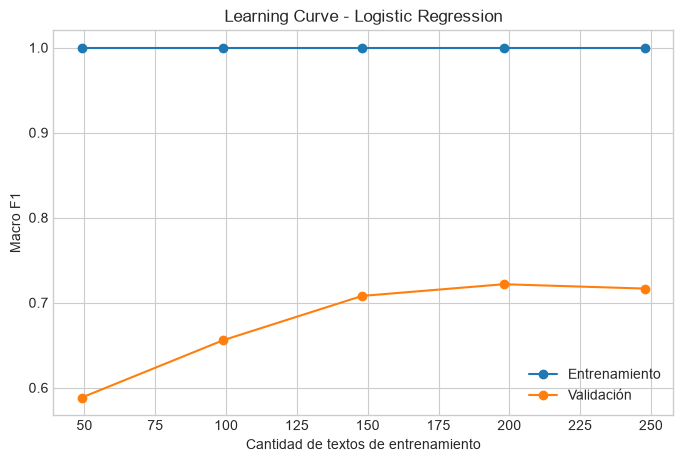

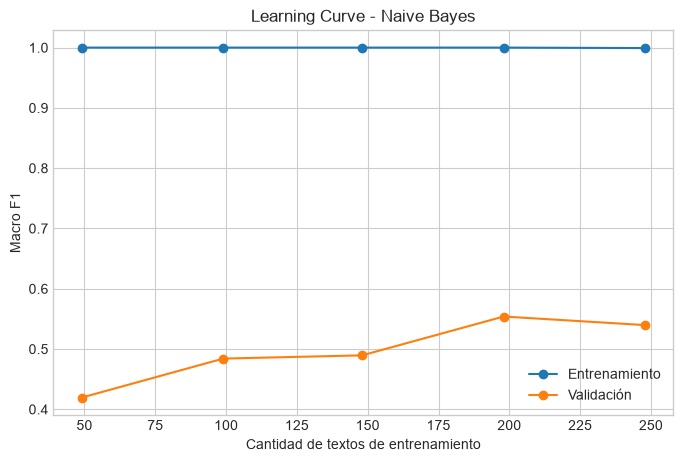

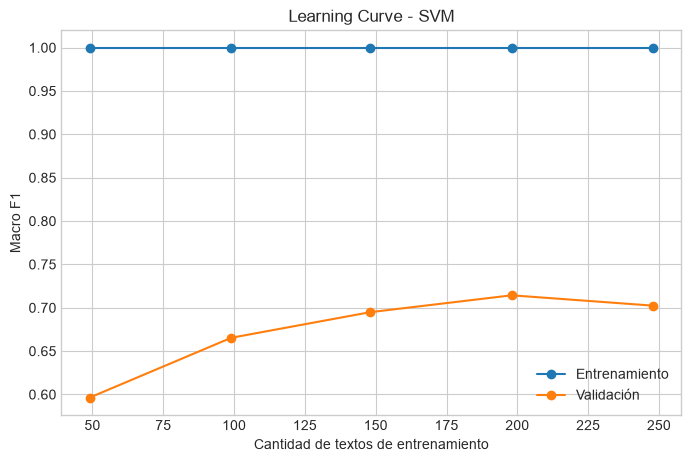

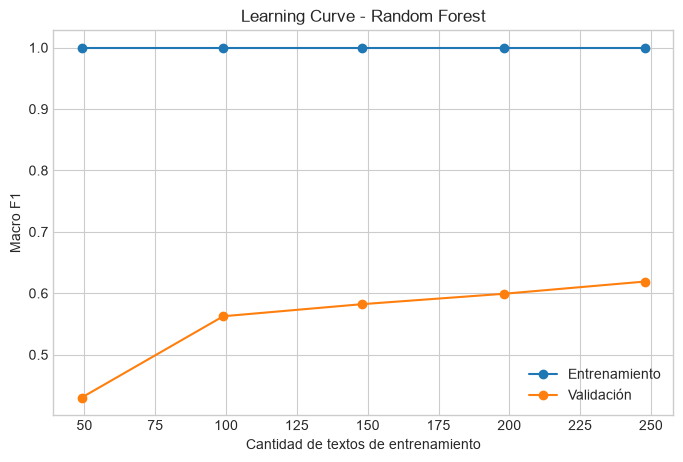

In [35]:
modelos = {
    "Logistic Regression": grid_lr.best_estimator_,
    "Naive Bayes": grid_nb.best_estimator_,
    "SVM": grid_svm.best_estimator_,
    "Random Forest": grid_rf.best_estimator_
}

for nombre, modelo in modelos.items():
    graficar_learning_curve(nombre, modelo, X_train, y_train)

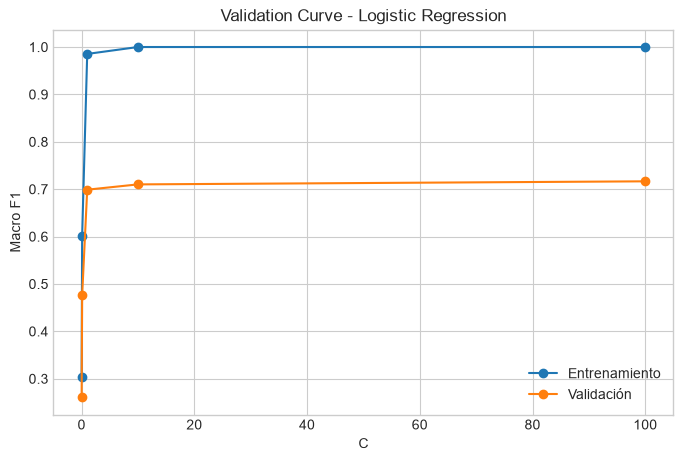

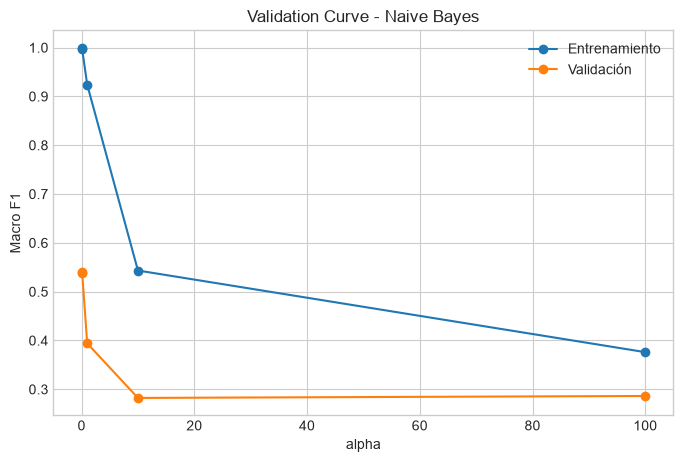

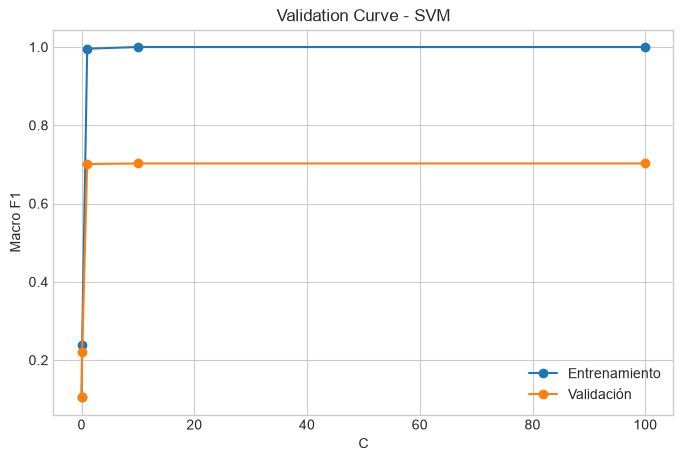

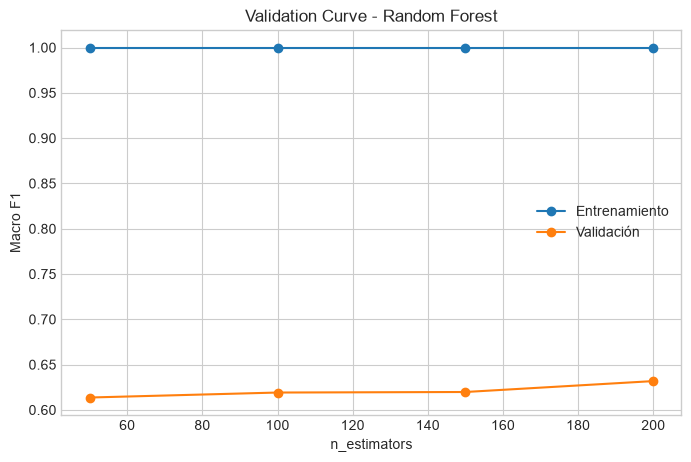

In [36]:
modelos = {
    "Logistic Regression": {
        "modelo": grid_lr.best_estimator_,
        "parametro": "classifier__C",
        "valores": [0.01, 0.1, 1, 10, 100]
    },
    "Naive Bayes": {
        "modelo": grid_nb.best_estimator_,
        "parametro": "classifier__alpha",
        "valores": [0.01, 0.1, 1, 10, 100]
    },
    "SVM": {
        "modelo": grid_svm.best_estimator_,
        "parametro": "classifier__C",
        "valores": [0.01, 0.1, 1, 10, 100]
    },
    "Random Forest": {
        "modelo": grid_rf.best_estimator_,
        "parametro": "classifier__n_estimators",
        "valores": [50, 100, 150, 200],
    }
}

for nombre, configuracion in modelos.items():
    graficar_validation_curve(
        nombre,
        configuracion["modelo"],
        X_train,
        y_train,
        configuracion["parametro"],
        configuracion["valores"]
    )

In [37]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV, learning_curve, validation_curve
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    roc_curve, roc_auc_score, precision_recall_curve
)

from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import GaussianNB

plt.style.use('seaborn-v0_8-whitegrid')

COLORS = {
    "train": "#1f77b4",
    "val": "#ff7f0e",
    "precision": "#2ca02c",
    "recall": "#d62728",
    "f1": "#9467bd",
    "roc": "#17becf"
}

def evaluate_model(name, pipeline, param_grid=None, complexity_param=None, complexity_range=None):

    print(f"\n{'='*60}")
    print(f"Modelo: {name}")
    print(f"{'='*60}")

    # GridSearch
    if param_grid:
        grid_search = GridSearchCV(pipeline, param_grid, cv=5, n_jobs=-1, scoring='accuracy')
        grid_search.fit(X_train, y_train)
        model = grid_search.best_estimator_
        print(f"Mejores parámetros: {grid_search.best_params_}")
    else:
        model = pipeline
        model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]

    train_acc = accuracy_score(y_train, model.predict(X_train))
    test_acc = accuracy_score(y_test, y_pred)

    print(f"Train Accuracy: {train_acc:.4f}")
    print(f"Test Accuracy: {test_acc:.4f}")

    fig, axes = plt.subplots(2, 3, figsize=(20, 11))
    fig.suptitle(f"{name} - Evaluación completa", fontsize=18, fontweight='bold')

    # Confusion Matrix
    cm = confusion_matrix(y_test, y_pred)
    ax = axes[0, 0]
    im = ax.imshow(cm, cmap='Blues')

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            ax.text(j, i, cm[i, j],
                    ha="center", va="center",
                    color="white" if cm[i, j] > cm.max()/2 else "black",
                    fontsize=12)

    ax.set_title("Confusion Matrix")
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")

    # ROC: usamos como clase positiva la segunda clase del modelo.
    pos_label = model.classes_[1]
    fpr, tpr, _ = roc_curve(y_test, y_prob, pos_label=pos_label)
    auc = roc_auc_score(y_test, y_prob, labels=model.classes_)

    ax = axes[0, 1]
    ax.plot(fpr, tpr, color=COLORS["roc"], lw=2, label=f"AUC = {auc:.3f}")
    ax.plot([0, 1], [0, 1], linestyle='--', color='gray')
    ax.set_title("ROC Curve")
    ax.set_xlabel("False Positive Rate")
    ax.set_ylabel("True Positive Rate")
    ax.legend()

    # Precision-Recall
    precision, recall, thresholds = precision_recall_curve(
        y_test, y_prob, pos_label=pos_label
    )

    ax = axes[0, 2]
    ax.plot(recall, precision, color=COLORS["precision"], lw=2)
    ax.set_title("Precision-Recall Curve")
    ax.set_xlabel("Recall")
    ax.set_ylabel("Precision")

    # Threshold curves
    f1_scores = 2 * (precision[:-1] * recall[:-1]) / (precision[:-1] + recall[:-1] + 1e-8)
    best_idx = f1_scores.argmax()
    best_thresh = thresholds[best_idx]

    ax = axes[1, 0]
    ax.plot(thresholds, precision[:-1], label="Precision", color=COLORS["precision"])
    ax.plot(thresholds, recall[:-1], label="Recall", color=COLORS["recall"])
    ax.plot(thresholds, f1_scores, label="F1", color=COLORS["f1"])
    ax.axvline(best_thresh, color='gray', linestyle='--', alpha=0.7)
    ax.set_title(f"Metrics vs Threshold (best={best_thresh:.2f})")
    ax.set_xlabel("Threshold")
    ax.set_ylabel("Score")
    ax.legend()

    # Learning Curve
    train_sizes, train_scores, val_scores = learning_curve(
        model, X, y, cv=5, n_jobs=-1,
        train_sizes=np.linspace(0.1, 1.0, 5)
    )

    ax = axes[1, 1]
    ax.plot(train_sizes, train_scores.mean(axis=1), marker='o',
            color=COLORS["train"], label="Train")
    ax.plot(train_sizes, val_scores.mean(axis=1), marker='o',
            color=COLORS["val"], label="Validation")

    ax.fill_between(train_sizes,
                    train_scores.mean(axis=1) - train_scores.std(axis=1),
                    train_scores.mean(axis=1) + train_scores.std(axis=1),
                    alpha=0.1, color=COLORS["train"])

    ax.fill_between(train_sizes,
                    val_scores.mean(axis=1) - val_scores.std(axis=1),
                    val_scores.mean(axis=1) + val_scores.std(axis=1),
                    alpha=0.1, color=COLORS["val"])

    ax.set_title("Learning Curve")
    ax.set_xlabel("Training Size")
    ax.set_ylabel("Accuracy")
    ax.legend()

    # Complexity Curve
    ax = axes[1, 2]

    if complexity_param and complexity_range:
        train_scores, val_scores = validation_curve(
            model, X, y,
            param_name=complexity_param,
            param_range=complexity_range,
            cv=5,
            n_jobs=-1
        )

        ax.plot(complexity_range, train_scores.mean(axis=1),
                marker='o', color=COLORS["train"], label="Train")

        ax.plot(complexity_range, val_scores.mean(axis=1),
                marker='o', color=COLORS["val"], label="Validation")

        ax.set_xscale("log" if max(complexity_range) / min(complexity_range) > 10 else "linear")
        ax.set_title("Complexity Curve")
        ax.set_xlabel(complexity_param.split("__")[-1])
        ax.set_ylabel("Accuracy")
        ax.legend()
    else:
        ax.set_title("No complexity parameter")

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()



Modelo: Logistic Regression (Normal vs Depression)
Mejores parámetros: {'classifier__C': 10}
Train Accuracy: 1.0000
Test Accuracy: 0.9756


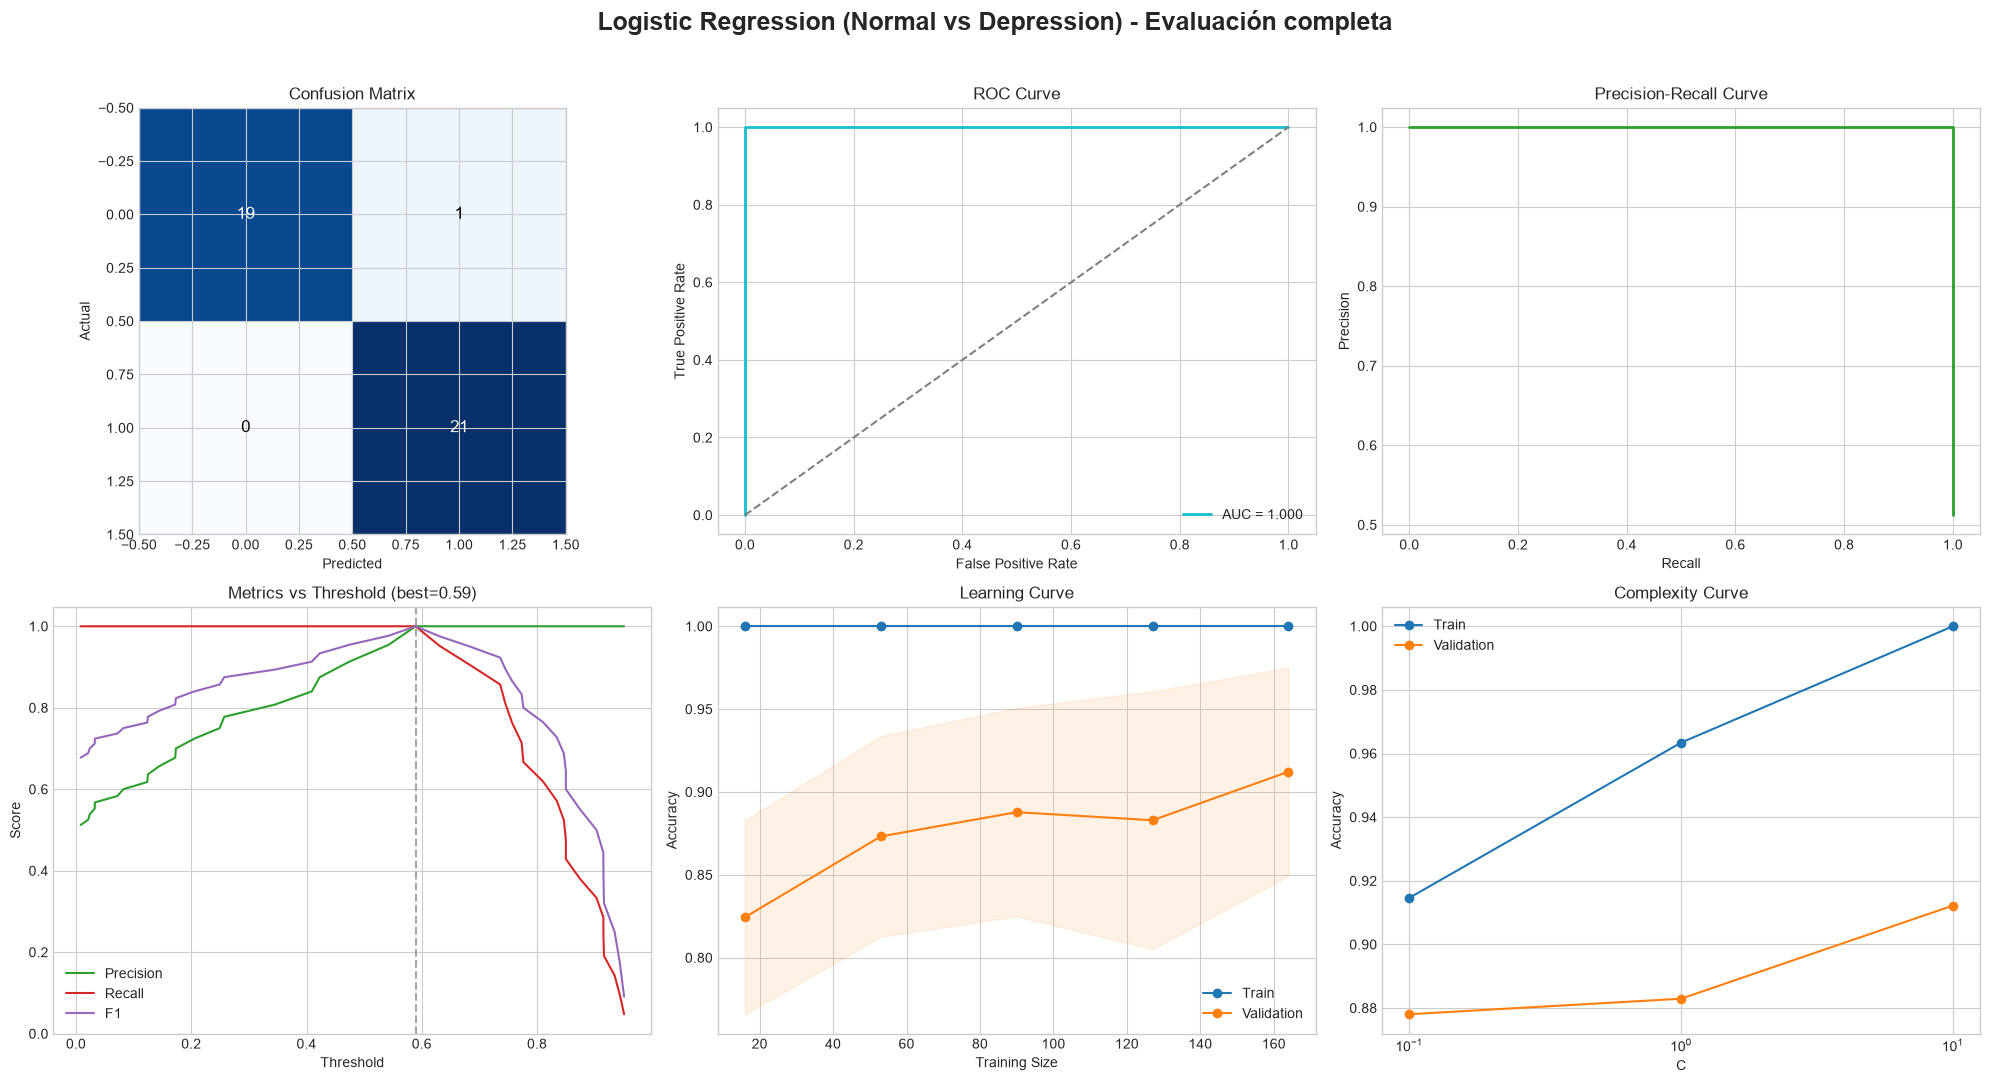

In [ ]:
from sklearn.model_selection import train_test_split

mascara_binaria = y.isin(['Normal', 'Depression'])
X_bin = X[mascara_binaria]
y_bin = y[mascara_binaria]
X_original, y_original = X, y
X_train_original, X_test_original = X_train, X_test
y_train_original, y_test_original = y_train, y_test
X, y = X_bin, y_bin

X_train, X_test, y_train, y_test = train_test_split(
    X_bin, y_bin, test_size=0.2, random_state=42, stratify=y_bin
)

pipeline_lr_binario = Pipeline([
    ('tfidf', TfidfVectorizer()),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

evaluate_model(
    name='Logistic Regression (Normal vs Depression)',
    pipeline=pipeline_lr_binario,
    param_grid={'classifier__C': [0.1, 1, 10]},
    complexity_param='classifier__C',
    complexity_range=[0.1, 1, 10]
)

# Recuperamos las variables multiclase para continuar con el notebook.
X, y = X_original, y_original
X_train, X_test = X_train_original, X_test_original
y_train, y_test = y_train_original, y_test_original

## 7. Evaluación final (hacerla cuando hayas elegido el modelo)

**Fuente:** `classification_report`, `confusion_matrix` y visualización de las Clases 5 y 6. Usá `X_test` una vez que la decisión esté tomada. Interpretá F1 de cada clase y Macro F1.

**Actividad 4:** recuperá el Pipeline ganador con `best_estimator_`, obtené `y_pred`, imprimí el reporte y la matriz de confusión. Esta sección está deliberadamente incompleta.

In [39]:
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

# TODO: después de seleccionar el ganador:
# mejor_pipeline = ...
# y_pred = mejor_pipeline.predict(X_test)
# print(classification_report(y_test, y_pred, zero_division=0))
# ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
# plt.show()


## 8. Reflexión para el TP

Respondé brevemente:

1. ¿Qué métrica elegiste para seleccionar modelos? ¿Por qué?
2. ¿Qué modelo y qué hiperparámetros ganaron durante validación cruzada?
3. ¿Qué sentimientos o categorías se confunden más, según la matriz de confusión final?
4. ¿Qué limitaciones impone este dataset de práctica (idioma, tamaño, dominio y etiquetas)?
5. **Transferencia al TP:** ¿qué deberías pedirle a quien hace preprocesamiento? Por ejemplo, columna de texto resultante, columna objetivo, variables adicionales, y confirmación de que ningún ajuste de TF-IDF usó test ni folds de validación.

### Camino posterior

- **Notebook 6:** SVM y Random Forest con los ejemplos de ensambles de la cátedra.
- **TP real:** reutilizar esta estructura sobre tweets y reemplazar las etiquetas por positivo/negativo/neutral.
- Los nombres de variables, fuentes y cualquier adaptación extra deberán quedar explicados en la entrega.
